# AirBnb

Notebook ini merupakan tahap persiapan untuk mengerjakan tugas pengembangan model regresi. Tugas anda adalah memastikan bahwa semua command dapat dijalankan dan menghasilkan dataset. Selain notebook ini memberikan gambaran proses penyiapan dataset untuk pemodelan

## 1. Mengimpor modul library

In [7]:
!pip install googlemaps

%matplotlib inline

import requests
import pandas as pd
import geopandas as gpd
import numpy as np
import googlemaps
from scipy.spatial.distance import cdist
import os
import re
import string
from shapely.geometry import Point
import googlemaps

In [8]:
# Change the working directory
output_directory = r"C:\Users\Sulthon Kamel M\Documents\S2\Perkuliahan\SIKC\Analitika Perkotaan"
os.chdir(output_directory)
print("Current working directory: {0}".format(os.getcwd()))

Current working directory: C:\Users\Sulthon Kamel M\Documents\S2\Perkuliahan\SIKC\Analitika Perkotaan


## 2. Download files

### a. download detailed listings file:

In [9]:
#Download data listing AirBnB di New York City tahun 2021
url = 'http://insideairbnb.com/get-the-data/united-states/ny/new-york-city/2023-03-06/data/listings.csv.gz'
r = requests.get(url)
with open('listings.csv.gz', 'wb') as fo:
    fo.write(r.content)

### b. download calendar file with prices

In [10]:
#Download data calendar AirBnB yang memiliki data harga listing
url = 'http://insideairbnb.com/get-the-data/united-states/ny/new-york-city/2023-03-06/data/calendar.csv.gz'
r = requests.get(url)
with open('calendar.csv.gz', 'wb') as fo:
    fo.write(r.content)

### c. download neighborhoods file

In [11]:
#Download data daftar neighborhoods di NYC
url = 'http://insideairbnb.com/get-the-data/united-states/ny/new-york-city/2023-03-06/data/neighbourhoods.geojson'
r = requests.get(url)
with open('neighbourhoods.geojson', 'wb') as fo:
    fo.write(r.content)

## 3. Setup Variabel

### a. parsing AirBnB price

In [17]:
lst = pd.read_csv('listings.csv.csv',low_memory=False) # Download data
lst['priceN'] = lst['price'].apply(lambda x: float(str(x).replace(',', '').strip('$'))) #Proses variable string ke float, dengan terlebih dahulu menghilangkan karakter "," dan '$'
lst = lst[lst.priceN != 0] #Hanya memilih observasi dengan nilai harga bukan Nol
lst['l_price'] = np.log(lst['priceN']) #Rubah ke nilai logaritmik
lst = lst[lst['l_price'].notna()] #hapus apabila ada missing values
lst = lst.reset_index(drop=True) #Reset row index

### b. construct GeoDataFrame

In [18]:
xys = lst[['longitude', 'latitude']].apply(lambda row: Point(*row), axis=1) # Buat objek berisi point lokasi AirBnB dari data longitude latitude

C:\Users\Sulthon Kamel M\anaconda3\lib\site-packages\pandas\core\dtypes\cast.py:122: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)


In [19]:
gdb = gpd.GeoDataFrame(lst.assign(geometry=xys), crs="+init=epsg:4326") #Buat geodataframe gdb

C:\Users\Sulthon Kamel M\anaconda3\lib\site-packages\pyproj\crs\crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [20]:
gdb

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,priceN,l_price,geometry
0,801749842377802394,https://www.airbnb.com/rooms/801749842377802394,20230306014634,2023-03-06,city scrape,A home away from home,The whole group will be comfortable in this sp...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,495455523,...,NaN,f,1,0,1,0,NaN,143.0,4.962845,POINT (-73.88853 40.64040)
1,765948794133787266,https://www.airbnb.com/rooms/765948794133787266,20230306014634,2023-03-06,city scrape,Brooklyn Refuge,Take a break and unwind at this peaceful oasis.,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,488760226,...,NaN,t,2,1,1,0,4.29,30.0,3.401197,POINT (-73.89433 40.64851)
2,636274456676328779,https://www.airbnb.com/rooms/636274456676328779,20230306014634,2023-03-06,city scrape,Villa Masino.,Close to beach Peaceful walk to park & beach...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,461263600,...,NaN,f,1,1,0,0,NaN,157.0,5.056246,POINT (-74.25191 40.50711)
3,768125251187660469,https://www.airbnb.com/rooms/768125251187660469,20230306014634,2023-03-06,city scrape,1-Bedroom Private Room with King Size Bed,Private room with king size bedroom near Sheep...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,475699129,...,NaN,t,7,0,7,0,5.17,89.0,4.488636,POINT (-73.95988 40.58349)
4,49248255,https://www.airbnb.com/rooms/49248255,20230306014634,2023-03-06,city scrape,Get the best of both worlds in Riverdale!,Welcome to the greatest location if you desire...,You will find within walking distance the Metr...,https://a0.muscache.com/pictures/e8e13cf7-44e9...,397288055,...,NaN,f,1,1,0,0,1.11,125.0,4.828314,POINT (-73.90709 40.90326)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42899,40342902,https://www.airbnb.com/rooms/40342902,20230306014634,2023-03-07,previous scrape,Cozy room in prime area,NaN,NaN,https://a0.muscache.com/pictures/19e0731e-c69e...,90429772,...,NaN,f,2,0,2,0,NaN,85.0,4.442651,POINT (-73.98801 40.72611)
42900,35257699,https://www.airbnb.com/rooms/35257699,20230306014634,2023-03-07,city scrape,Hell's Kitchen /Times Sq - Comfortable 2 BDR Flat,"Location Location. Hell's Kitchen, Times Squar...",NaN,https://a0.muscache.com/pictures/51ede1d9-e522...,264962468,...,NaN,f,1,1,0,0,4.79,208.0,5.337538,POINT (-73.99027 40.76215)
42901,52491515,https://www.airbnb.com/rooms/52491515,20230306014634,2023-03-07,city scrape,Cozy 3 bedroom apt in the heart of Lower East ...,This comfortable apartment in the heart of Low...,NaN,https://a0.muscache.com/pictures/824c07e0-2bf1...,305489297,...,NaN,f,6,6,0,0,0.43,125.0,4.828314,POINT (-73.99111 40.71733)
42902,48158801,https://www.airbnb.com/rooms/48158801,20230306014634,2023-03-07,previous scrape,Spacious Loft Space / Photo studio in Bushwick,Looking for a two month subleter. LGBTQ+ and a...,NaN,https://a0.muscache.com/pictures/cb171d83-e0ab...,6600525,...,NaN,f,1,0,1,0,NaN,50.0,3.912023,POINT (-73.91766 40.68735)


### c. create variables

In [21]:
# Create a functio to clean up listing text
def cleaningText(text):
    text = text.replace('\n', ' ') # replace new line into space
    text = text.translate(str.maketrans('', '', string.punctuation)) # remove all punctuations
    text = text.strip(' ') # remove characters space from both left and right text
    text = text.lower() #change text to lower case
    return text

In [22]:
gdb['amenities_clean'] = gdb['amenities'].apply(cleaningText) #Apply fungsi pembersihan text

### d. extracting amenity variables

In [23]:
# Swimming pool variable
gdb['pool'] = 0 
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'pool' in r:
        gdb.loc[i, 'pool'] = 1

In [24]:
# Kitchen variable
gdb['kitchen'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'kitchen' in r:
        gdb.loc[i, 'kitchen'] = 1


In [25]:
# Possible for long stay
gdb['long_stay'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'long term stays' in r:
        gdb.loc[i, 'long_stay'] = 1


In [26]:
# Availability of Wifi
gdb['wifi'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'wifi' in r:
        gdb.loc[i, 'wifi'] = 1


In [27]:
# Has cable tv
gdb['cable_tv'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'cable tv' in r:
        gdb.loc[i, 'cable_tv'] = 1

In [28]:
# Has netflix 
gdb['netflix'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'netflix' in r:
        gdb.loc[i, 'netflix'] = 1

In [29]:
# Provides extra pillows and blankets
gdb['xtra_pillow'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'extra pillows and blankets' in r:
        gdb.loc[i, 'xtra_pillow'] = 1

In [30]:
# Luggage dropoff allowed
gdb['luggage_dropoff'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'luggage dropoff' in r:
        gdb.loc[i, 'luggage_dropoff'] = 1

In [31]:
# Has Air conditioning
gdb['air_conditioning'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'air conditioning' in r:
        gdb.loc[i, 'air_conditioning'] = 1

In [32]:
# Free street parking
gdb['free_parking'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'free street parking' in r:
        gdb.loc[i, 'free_parking'] = 1

In [33]:
# Washer
gdb['washer'] = 0
for i in range(gdb.shape[0]):
    r = gdb.loc[i, 'amenities_clean']
    if 'washer' in r:
        gdb.loc[i, 'washer'] = 1

### e. create a distance variable from Time Square

In [35]:
!pip install geopy
import geopy

from geopy.geocoders import Nominatim
geolocator = Nominatim(user_agent="myGeocoder") #Create geolocator obejct dari paket Nominatim

In [36]:
#Untuk menggunakan geolocator cukup ketikkan nama lokasi yang ingin di geolocating
bp = geolocator.geocode("Times Square, New York, US")
bp

Location(Times Square, Manhattan, New York County, City of New York, New York, United States, (40.75701215, -73.98597092538824, 0.0))

In [37]:
b_ll = bp.longitude, bp.latitude
b_ll

(-73.98597092538824, 40.75701215)

#### Then calculate distance to the Times Square from each house:

In [38]:
# USA Contiguous Albers Equal Area (m.)
# http://epsg.io/102003
tgt_crs = "+proj=aea +lat_1=29.5 +lat_2=45.5 +lat_0=37.5 "\
          "+lon_0=-96 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs"

b_xy = gpd.GeoSeries(Point(b_ll), crs=gdb.crs).to_crs(tgt_crs)[0]
b_xy = (b_xy.x, b_xy.y)
# Calculate distance in Km.
d2b = lambda pt: cdist([(pt.x, pt.y)], [b_xy])[0][0] / 1000

<AxesSubplot:>

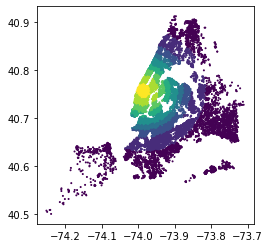

In [40]:
!pip install mapclassify
import mapclassify

gdb['d2tsquare'] = gdb['geometry'].to_crs(tgt_crs)\
                                 .apply(d2b)
gdb.plot(column='d2tsquare', scheme='quantiles', k=9,
         cmap='viridis_r', s=1)

### Creating Coastal neighborhood?

**NOTE**: Still some mistakes it seems but `neighborhood_cleansed` works much better than `neighborhood`.

In [41]:
coastal_neighborhoods = ["Breezy Point", "Neponsit", "Belle Harbor", "Rockaway Park", "Rockaway Beach", "Arverne", 
                         "Edgemere", "Far Rockaway", "Bayswater", "Broad Channel", "Howard Beach", "East New York", 
                         "Canarsie", "Bergen Beach", "Mill Basin", "Gerritsen Beach", "Manhattan Beach", "Brighton Beach", 
                         "Sheepshead Bay", "Coney Island", "Sea Gate", "Gravesend", "Bath Beach", "Fort Hamilton", 
                         "Bay Ridge", "Sunset Park", "Red Hook", "Columbia St", "Brooklyn Heights", "DUMBO", "Vinegar Hill", 
                         "Williamsburg", "Greenpoint", "Long Island City", "Astoria", "Ditmars Steinway", "College Point", 
                         "Whitestone", "Bayside", "Little Neck", "City Island", "Country Club", "Throgs Neck", "Castle Hill", 
                         "Clason Point", "Hunts Point", "Mott Haven", "East Harlem", "Roosevelt Island", "Midtown", 
                         "Kips Bay", "Stuyvesant Town", "Lower East Side", "Two Bridges", "Battery Park City", "Tribeca", 
                         "West Village", "Chelsea", "Hell's Kitchen", "Upper West Side", "Morningside Heights", 
                         "Harlem", "Washington Heights", "Inwood", "Spuyten Duyvil", "Riverdale", "North Riverdale", 
                         "Bloomfield", "Mariners Harbor", "Port Richmond", "Randall Manor", "New Brighton", "St. George", 
                         "Tompkinsville", "Stapleton Heights", "Clifton", "Rosebank", "Shore Acres", "Fort Wadsworth", 
                         "Arrochar", "South Beach", "Midland Beach", "New Dorp Beach", "Oakwood", "Bay Terrace", 
                         "Great Kills", "Eltingville", "Prince's Bay", "Pleasant Plains", "Tottenville", "Charleston", 
                         "Rossville", "Chelsea, Staten Island"]


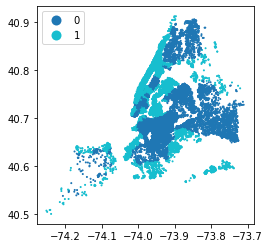

In [42]:
#Buat fungsi untuk mengecek apakah rumah AirBnB berada di lingkungan pantai
def coastal(neigh):
    if neigh in coastal_neighborhoods:
        return 1
    else:
        return 0
gdb['coastal_neig'] = gdb['neighbourhood_cleansed'].apply(coastal)

gdb.plot(column='coastal_neig', s=1,
         categorical=True, legend=True);

### f. creating large neighborhood variable

We keep only observations in neighborhoods with more than 25 AirBnb houses so FE on neighborhood make sense.

In [43]:
lrg_nei = gdb.groupby('neighbourhood_cleansed').size() > 25
gdb['lrg_nei'] = gdb['neighbourhood_cleansed'].map(lrg_nei)

In [44]:
gdb

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,cable_tv,netflix,xtra_pillow,luggage_dropoff,air_conditioning,free_parking,washer,d2tsquare,coastal_neig,lrg_nei
0,801749842377802394,https://www.airbnb.com/rooms/801749842377802394,20230306014634,2023-03-06,city scrape,A home away from home,The whole group will be comfortable in this sp...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,495455523,...,0,0,0,0,1,1,0,15.402523,1,True
1,765948794133787266,https://www.airbnb.com/rooms/765948794133787266,20230306014634,2023-03-06,city scrape,Brooklyn Refuge,Take a break and unwind at this peaceful oasis.,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,488760226,...,0,0,0,0,0,0,0,14.375051,1,True
2,636274456676328779,https://www.airbnb.com/rooms/636274456676328779,20230306014634,2023-03-06,city scrape,Villa Masino.,Close to beach Peaceful walk to park & beach...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,461263600,...,0,0,0,0,0,0,0,35.790904,1,False
3,768125251187660469,https://www.airbnb.com/rooms/768125251187660469,20230306014634,2023-03-06,city scrape,1-Bedroom Private Room with King Size Bed,Private room with king size bedroom near Sheep...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,475699129,...,0,0,0,0,0,0,0,19.557517,1,True
4,49248255,https://www.airbnb.com/rooms/49248255,20230306014634,2023-03-06,city scrape,Get the best of both worlds in Riverdale!,Welcome to the greatest location if you desire...,You will find within walking distance the Metr...,https://a0.muscache.com/pictures/e8e13cf7-44e9...,397288055,...,0,0,0,0,0,1,1,17.657170,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42899,40342902,https://www.airbnb.com/rooms/40342902,20230306014634,2023-03-07,previous scrape,Cozy room in prime area,NaN,NaN,https://a0.muscache.com/pictures/19e0731e-c69e...,90429772,...,0,0,0,0,0,1,0,3.465136,0,True
42900,35257699,https://www.airbnb.com/rooms/35257699,20230306014634,2023-03-07,city scrape,Hell's Kitchen /Times Sq - Comfortable 2 BDR Flat,"Location Location. Hell's Kitchen, Times Squar...",NaN,https://a0.muscache.com/pictures/51ede1d9-e522...,264962468,...,0,0,1,0,1,0,1,0.678722,1,True
42901,52491515,https://www.airbnb.com/rooms/52491515,20230306014634,2023-03-07,city scrape,Cozy 3 bedroom apt in the heart of Lower East ...,This comfortable apartment in the heart of Low...,NaN,https://a0.muscache.com/pictures/824c07e0-2bf1...,305489297,...,0,0,0,0,0,0,0,4.465061,1,True
42902,48158801,https://www.airbnb.com/rooms/48158801,20230306014634,2023-03-07,previous scrape,Spacious Loft Space / Photo studio in Bushwick,Looking for a two month subleter. LGBTQ+ and a...,NaN,https://a0.muscache.com/pictures/cb171d83-e0ab...,6600525,...,0,0,0,0,0,0,0,9.675657,0,True


### g. room type

In [45]:
rt = pd.get_dummies(gdb['room_type'], prefix='rt').rename(columns=lambda x: x.replace(' ', '_'))

In [46]:
rt

,rt_Entire_home/apt,rt_Hotel_room,rt_Private_room,rt_Shared_room
0,0,0,1,0
1,0,0,1,0
2,1,0,0,0
3,0,0,1,0
4,1,0,0,0
...,...,...,...,...
42899,0,0,1,0
42900,1,0,0,0
42901,1,0,0,0
42902,0,0,1,0


### i. property type

In [47]:
def simplify(p):
    bigs = ['House', 'Apartment', 'Condominium', 'Townhouse']
    if p in bigs:
        return p
    else:
        return 'Other'

gdb['property_group'] = gdb['property_type'].apply(simplify)
pg = pd.get_dummies(gdb['property_group'], prefix='pg')

In [48]:
pg

,pg_Other
0,1
1,1
2,1
3,1
4,1
...,...
42899,1
42900,1
42901,1
42902,1


### List to keep

In [49]:
xs = ['accommodates',  'bedrooms', 
      'beds', 'neighbourhood_cleansed', 'pool','kitchen','long_stay','wifi','cable_tv','netflix','xtra_pillow',
      'luggage_dropoff','air_conditioning','free_parking','washer',
      'd2tsquare', 'coastal_neig', 'lrg_nei',
      'priceN', 'l_price',
      'geometry', 'id']

## Write out

Pada bagian ini anda akan memperoleh dataset final. Pastikan keseluruhan proses telah dijalankan

In [50]:
final = gdb[xs].join(pg).join(rt).rename(columns={'priceN': 'price'}).loc[gdb['lrg_nei']==True, :].drop(['lrg_nei'], axis=1).dropna()

In [51]:
final

,accommodates,bedrooms,beds,neighbourhood_cleansed,pool,kitchen,long_stay,wifi,cable_tv,netflix,...,coastal_neig,price,l_price,geometry,id,pg_Other,rt_Entire_home/apt,rt_Hotel_room,rt_Private_room,rt_Shared_room
0,2,1.0,1.0,Canarsie,0,1,0,1,0,0,...,1,143.0,4.962845,POINT (-73.88853 40.64040),801749842377802394,1,0,0,1,0
1,1,1.0,1.0,Canarsie,0,1,0,1,0,0,...,1,30.0,3.401197,POINT (-73.89433 40.64851),765948794133787266,1,0,0,1,0
3,2,3.0,1.0,Sheepshead Bay,0,1,0,1,0,0,...,1,89.0,4.488636,POINT (-73.95988 40.58349),768125251187660469,1,0,0,1,0
5,3,1.0,1.0,Flushing,0,1,0,1,0,0,...,0,63.0,4.143135,POINT (-73.82608 40.76350),52059982,1,0,0,1,0
8,1,1.0,1.0,Richmond Hill,0,1,0,1,0,0,...,0,49.0,3.891820,POINT (-73.82713 40.70015),654508528815045267,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42898,5,2.0,3.0,Lower East Side,0,1,0,1,0,0,...,1,350.0,5.857933,POINT (-73.98424 40.72030),150804,1,1,0,0,0
42899,1,1.0,1.0,East Village,0,1,0,1,0,0,...,0,85.0,4.442651,POINT (-73.98801 40.72611),40342902,1,0,0,1,0
42900,6,2.0,3.0,Hell's Kitchen,0,1,1,1,0,0,...,1,208.0,5.337538,POINT (-73.99027 40.76215),35257699,1,1,0,0,0
42901,3,3.0,3.0,Lower East Side,0,1,0,1,0,0,...,1,125.0,4.828314,POINT (-73.99111 40.71733),52491515,1,1,0,0,0


In [52]:
final = final.rename(columns=dict(neighbourhood_cleansed='neighborhood', 
                          coastal_neig='coastal',
                          l_price = 'log_price'))

In [53]:
data = final[['accommodates', 'bedrooms', 
      'beds', 'neighborhood', 'pool','kitchen','long_stay','wifi','cable_tv','netflix','xtra_pillow',
      'luggage_dropoff','air_conditioning','free_parking','washer',
      'd2tsquare', 'coastal', 'pg_Other', 'rt_Entire_home/apt', 'rt_Hotel_room', 'rt_Private_room', 'rt_Shared_room',
      'price', 'log_price']]

In [54]:
data.describe()

,accommodates,bedrooms,beds,pool,kitchen,long_stay,wifi,cable_tv,netflix,xtra_pillow,...,washer,d2tsquare,coastal,pg_Other,rt_Entire_home/apt,rt_Hotel_room,rt_Private_room,rt_Shared_room,price,log_price
count,37538.000000,37538.000000,37538.000000,37538.000000,37538.000000,37538.000000,37538.000000,37538.0,37538.000000,37538.000000,...,37538.000000,37538.000000,37538.000000,37538.0,37538.000000,37538.000000,37538.000000,37538.000000,37538.000000,37538.000000
mean,3.020859,1.401300,1.685625,0.030103,0.889765,0.327109,0.981059,0.0,0.105893,0.339922,...,0.466967,7.841129,0.454819,1.0,0.538947,0.004182,0.442512,0.014359,199.766050,4.864547
std,2.129994,0.789932,1.183455,0.170873,0.313187,0.469164,0.136318,0.0,0.307704,0.473689,...,0.498914,4.920973,0.497961,0.0,0.498487,0.064537,0.496691,0.118966,797.677646,0.794825
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.051891,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,10.000000,2.302585
25%,2.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.0,0.000000,0.000000,...,0.000000,4.179992,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,75.000000,4.317488
50%,2.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.0,0.000000,0.000000,...,0.000000,7.564285,0.000000,1.0,1.000000,0.000000,0.000000,0.000000,125.000000,4.828314
75%,4.000000,2.000000,2.000000,0.000000,1.000000,1.000000,1.000000,0.0,0.000000,1.000000,...,1.000000,10.301174,1.000000,1.0,1.000000,0.000000,1.000000,0.000000,205.000000,5.323010
max,16.000000,16.000000,21.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,...,1.000000,27.465408,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,85170.000000,11.352405


## Instruksi Tugas

Anda diminta untuk melakukan tugas-tugas berikut:
1. Melakukan Penyiapan data
2. Melakukan Feature Selection
3. Pengembangan Model Regresi Beserta Evaluasi. Laporkan hasil evaluasi dengan menggunakan MAP, RMSE, dan R2. Diskusikan mana model yang anda anggap terbaik
    - Model Regresi Multi-variate
    - Model Regresi Suport Vector Model
    - Model Regresi Random Forest
4. Gunakan Model regresi terbaik yang anda pilih, dan lakukan prediksi untuk nilai-nilai sebagai berikut:
    - accommodates = 2
    - bedrooms = 1
    - beds = 1
    - pool = 1
    - kitchen = 0
    - long_stay = 0
    - wifi = 1
    - cable_tv = 0
    - netflix = 0
    - xtra_pillow = 1
    - rt_Entire_home/apt' = 0
    - rt_Hotel_room = 0
    - rt_Private_room = 1
    - rt_Shared_room = 0
    - luggage_dropoff = 1
    - air_conditioning = 0
    - free_parking = 1
    - washer = 1
    - d2tsquare = 5
    - coastal = 1

### 1. Penyiapan data

### 2. Feature Selection

### 3. Pengembangan Model Regresi Beserta Evaluasi

### 3.a Regresi Multivariate 

### 3.b Model Regresi Suport Vector Model

### 3.c Model Regresi Random Forest

### 4. Prediksi Harga Listing berdasarkan Model Terpilih